In [ ]:
#اول كود
from bs4 import BeautifulSoup
import requests, csv, os, time, random

csv_filename = "/content/drive/MyDrive/aitnews_infinite_dataset.csv"
headers = { "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36" }

file_exists = os.path.exists(csv_filename)
if not file_exists or os.path.getsize(csv_filename) == 0:
    with open(csv_filename, "w", encoding="utf-8-sig", newline="") as file:
        csv.writer(file).writerow(["النوع", "شرح المقال"])
    print("📝 تم إنشاء ملف جديد بالترتيب: [ النوع، شرح المقال]")
else:
    print("📂 الملف موجود مسبقاً، سيتم استكمال السحب والإضافة عليه.")

existing_texts = set()
page_num = 1
print(f"🚀 انطلق السكربت... جاري السحب اللانهائي بدءاً من الصفحة [{page_num}]!")

while True:
    url = f"https://aitnews.com/latest-it-news/page/{page_num}/"
    print(f"\n📖 جاري فحص الصفحة رقم: {page_num} -> {url}")

    try:
        html = requests.get(url, headers=headers, timeout=10).text
        soup = BeautifulSoup(html, "lxml")
        box = soup.find("div", class_="mag-box-container clearfix")#جبلي .....
        articles = box.find_all("li", class_="post-item") if box else []
    except Exception as e:
        print(f"🛑 حدث خطأ في الصفحة أو توقف الاتصال: {e}")
        break

    if not articles:
        print("🎉 مبروك! تم سحب جميع الصفحات المتاحة في الموقع بالكامل.")
        break

    with open(csv_filename, "a", encoding="utf-8-sig", newline="") as file:
        writer = csv.writer(file)

        for index, article in enumerate(articles, start=1):
            title = article.find("h2", class_="post-title")
            link = title.find("a") if title else None
            if not link: continue

            article_url = link["href"]
            time.sleep(random.uniform(0.3, 1))

            try:
                art_html = requests.get(article_url, headers=headers, timeout=10).text
                art_soup = BeautifulSoup(art_html, "lxml")


                cat = art_soup.find("span", class_="post-cat-wrap")
                category = cat.find("a").get_text(strip=True) if cat and cat.find("a") else "تقنية"

                body = art_soup.find("div", class_=lambda x: x and "entry-content" in x)
                if not body: continue
            except Exception:
                continue

            for unwanted in body.find_all("div", class_=lambda x: x and ("post-bottom-tags" in x or "post-shortlink" in x)):
                unwanted.decompose()
            for a in body.find_all("a"):
                a.replace_with(a.get_text(strip=True))

            text, seen_texts = "", set()
            elements = body.find_all(["h1", "h2", "h3", "h4", "p", "li", "span", "strong", "em"])
            for element in elements:
                element_text = element.get_text(strip=True)
                if element_text and element_text not in seen_texts:
                    seen_texts.add(element_text)
                    if element.name in ["h1", "h2", "h3", "h4"]:
                        text += f"\n{element_text}\n\n"
                    elif element.name == "li":
                        text += f"• {element_text}\n"
                    else:
                        text += f"{element_text}\n\n"
                        text = text.strip()

            if len(text) >= 50 and text not in existing_texts:
                writer.writerow([ category, text])
                existing_texts.add(text)
                print(f"   ✅ [مقال {index}]| التصنيف: [{category}]")
            else:
                print(f"   ⏭️ [مقال {index}] تخطي (مكرر أو قصير جداً)")

    page_num += 1
    time.sleep(3)

print(f"\n📁 اكتمل العمل! الملف يمتلئ الآن في الـ Google Drive.")

📂 الملف موجود مسبقاً، سيتم استكمال السحب والإضافة عليه.
🚀 انطلق السكربت... جاري السحب اللانهائي بدءاً من الصفحة [1]!

📖 جاري فحص الصفحة رقم: 1 -> https://aitnews.com/latest-it-news/page/1/
   ✅ [مقال 1]| التصنيف: [الأمن السيبراني]
   ✅ [مقال 2]| التصنيف: [أخبار قطاع الأعمال]
   ✅ [مقال 3]| التصنيف: [الأخبار التقنية]
   ✅ [مقال 4]| التصنيف: [الأمن السيبراني]
   ✅ [مقال 5]| التصنيف: [أخبار قطاع الأعمال]
   ✅ [مقال 6]| التصنيف: [أجهزة محمولة]
   ✅ [مقال 7]| التصنيف: [أخبار الإنترنت]
   ✅ [مقال 8]| التصنيف: [الأمن السيبراني]
   ✅ [مقال 9]| التصنيف: [أجهزة محمولة]
   ✅ [مقال 10]| التصنيف: [أخبار الإنترنت]


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import time
from urllib.parse import urljoin
import csv

original_file_path = "/content/drive/MyDrive/ahmed جديد.csv"
base_category_url = "https://www.a7la-home.com/category/tech/windows/"

max_pages = 100

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}


try:
    df_original = pd.read_csv(
        original_file_path,
        on_bad_lines='skip',
        engine='python',
        encoding='utf-8-sig'
    )
    if "التصنيف" in df_original.columns and "شرح المقال" in df_original.columns:
        df_original = df_original[["التصنيف", "شرح المقال"]]
    else:
        df_original = pd.DataFrame(columns=["التصنيف", "شرح المقال"])

    print(f"📖 تم قراءة الملف الأصلي بنجاح. يحتوي حالياً على: {len(df_original):,} مقال.")

except FileNotFoundError:
    df_original = pd.DataFrame(columns=["التصنيف", "شرح المقال"])
    print("⚠️ لم يتم العثور على الملف الأصلي، سيتم إنشاء ملف جديد عند الحفظ.")


scraped_articles = []
print(f"🚀 بدء سحب المقالات والإضافة المباشرة...")

for page in range(6, max_pages + 1):
    page_url = base_category_url if page == 1 else f"{base_category_url}page/{page}/"
    print(f"\n📑 جاري فتح صفحة الأرشيف رقم ({page}): {page_url}")

    try:
        response = requests.get(page_url, headers=headers, timeout=12)

        if response.status_code != 200:
            print(f"⚠️ نهاية الصفحات أو تعذر الوصول (كود: {response.status_code}).")
            break

        soup = BeautifulSoup(response.content, "html.parser")
        titles_a = soup.select("h2.entry-title a")

        if not titles_a:
            print("ℹ️ لم يتم العثور على مقالات في هذه الصفحة.")
            break

        print(f"🔍 تم العثور على {len(titles_a)} مقال في الصفحة {page}...")

        for a_tag in titles_a:
            full_article_url = a_tag.get("href")
            if not full_article_url:
                continue

            full_article_url = urljoin("https://www.a7la-home.com", full_article_url)

            try:
                art_resp = requests.get(full_article_url, headers=headers, timeout=8)
                if art_resp.status_code != 200:
                    continue

                art_soup = BeautifulSoup(art_resp.content, "html.parser")
                content_div = art_soup.select_one("div.entry-content, div.post-content")

                if content_div:
                    paragraphs = content_div.find_all("p")
                    if paragraphs:
                        full_content = " ".join([p.get_text(strip=True) for p in paragraphs if p.get_text(strip=True)])
                    else:
                        full_content = content_div.get_text(separator=" ", strip=True)

                    clean_content = full_content.strip()

                    if len(clean_content) > 50:
                        scraped_articles.append({
                            "التصنيف": "أنظمة تشغيل",
                            "شرح المقال": clean_content
                        })
                        print(f"  ✅ تم سحب وإضافة: {a_tag.get_text(strip=True)[:35]}...")

            except Exception:
                continue

            time.sleep(0.1)

    except Exception as err:
        print(f"❌ خطأ بالاتصال بالصفحة {page}: {err}")
        break

if scraped_articles:
    df_new = pd.DataFrame(scraped_articles)[["التصنيف", "شرح المقال"]]

    df_combined = pd.concat([df_original, df_new], ignore_index=True)

    df_combined.to_csv(
        original_file_path,
        index=False,
        encoding="utf-8-sig",
        quoting=csv.QUOTE_MINIMAL
    )

    print("\n" + "=" * 60)
    print("🎉 تم الحفظ والدمج المباشر بنجاح!")
    print(f"➕ المقالات الجديدة المضافة: {len(df_new):,}")
    print(f"📊 إجمالي المقالات بالملف النهائي الآن: {len(df_combined):,}")
    print("=" * 60)
else:
    print("\n⚠️ لم يتم سحب أي مقالات جديدة.")

⚠️ لم يتم العثور على الملف الأصلي، سيتم إنشاء ملف جديد عند الحفظ.
🚀 بدء سحب المقالات والإضافة المباشرة...

📑 جاري فتح صفحة الأرشيف رقم (6): https://www.a7la-home.com/category/tech/windows/page/6/
🔍 تم العثور على 15 مقال في الصفحة 6...
  ✅ تم سحب وإضافة: حل مشكلة عدم تعرف Windows 11 على لو...
  ✅ تم سحب وإضافة: حلول فعّالة لمشكلة توقّف رؤى Copilo...
  ✅ تم سحب وإضافة: طرق آمنة لقفل جهاز ويندوز عن بعد با...
  ✅ تم سحب وإضافة: حلول فعّالة لمشاكل النسخ الاحتياطي ...
  ✅ تم سحب وإضافة: اختفاء قائمة السياق في OneDrive على...
  ✅ تم سحب وإضافة: أفضل تطبيقات ويندوز لتصوير الشاشة و...
  ✅ تم سحب وإضافة: أهم الإعدادات الأربعة لتبسيط استخدا...


KeyboardInterrupt: 

In [ ]:
#الكزد الثالث


from bs4 import BeautifulSoup
import requests
import csv
import sys
import os
import time
from urllib.parse import urljoin
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

csv.field_size_limit(sys.maxsize)

destination_csv_filename = "/content/drive/MyDrive/ahmed جديد.csv"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
    "Accept-Language": "ar,en-US;q=0.7,en;q=0.3"
}

base_url = "https://aiarabic.com/archives/category/%D8%A3%D8%AE%D8%A8%D8%A7%D8%B1/page/800"
site_url = "https://aiarabic.com"

destination_file_exists = os.path.exists(destination_csv_filename) and os.path.getsize(destination_csv_filename) > 0

if not destination_file_exists:
    with open(destination_csv_filename, "w", encoding="utf-8-sig", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["التصنيف", "شرح المقال"])
    print("📝 تم إنشاء ملف جديد في الدرايف وكتابة العناوين (التصنيف، شرح المقال).")
else:
    print("📄 الملف الوجهة موجود مسبقاً، سيتم إضافة البيانات الجديدة بالأسفل.")

existing_urls = set()
total_saved = 0
current_url = base_url
page_counter = 800

session = requests.Session()
session.headers.update(headers)

def scrape_single_article(article_url):
    article_url = urljoin(site_url, article_url)
    if article_url in existing_urls:
        return None

    try:
        art_resp = session.get(article_url, timeout=15)
        if art_resp.status_code != 200:
            return None

        art_soup = BeautifulSoup(art_resp.text, "html.parser")

        title_tag = art_soup.select_one("h1.post-title, h1.entry-title, .post-title")
        title_text = title_tag.get_text(strip=True) if title_tag else "بدون عنوان"

        body = art_soup.select_one(".entry-content, .post-content, div[class*='content']")
        if not body:
            return None

        for unwanted in body.find_all(["script", "style", "ins", "nav", "footer"]):
            unwanted.decompose()

        article_text = body.get_text(" ", strip=True)

        if len(article_text) < 100:
            sub_elements = body.find_all(["p", "div", "blockquote"])
            article_text = "\n\n".join([el.get_text(strip=True) for el in sub_elements if el.get_text(strip=True)]).strip()

        return ["الذكاء الاصطناعي", article_text, title_text, article_url]
    except:
        return None

while current_url:
    print("\n" + "=" * 70)
    print(f"🚀 جاري سحب صفحة الموقع رقم: {page_counter}")
    print(f"🔗 الرابط الحالي: {current_url}")

    try:
        response = session.get(current_url, timeout=15)

        if response.status_code == 400:
            print("⚠️ السيرفر أعطى إشارة حظر مؤقت (400). جاري تجديد الاتصال والاستراحة...")
            session.cookies.clear()
            time.sleep(10)
            continue

        response.raise_for_status()
    except Exception as e:
        print("❌ خطأ توقف حرج في جلب الصفحة الرئيسية:", e)
        break

    soup = BeautifulSoup(response.text, "html.parser")

    links_elements = soup.select('h5.post-title a[href]')
    valid_links = []
    seen_hrefs = set()
    for a in links_elements:
        href = a.get("href")
        if href and href not in seen_hrefs and "/category/" not in href:
            seen_hrefs.add(href)
            valid_links.append(href)

    print(f"📰 عدد المقالات المكتشفة في هذه الصفحة: {len(valid_links)}")

    if valid_links:
        with ThreadPoolExecutor(max_workers=5) as executor:
            results = executor.map(scrape_single_article, valid_links)
            with open(destination_csv_filename, "a", encoding="utf-8-sig", newline="") as file:
                writer = csv.writer(file)
                for result in results:
                    if result:
                        writer.writerow([result[0], result[1]])
                        existing_urls.add(result[3])
                        total_saved += 1
                        print(f"   ⚡️ [تم السحب الفوري]: {result[2][:40]}...")
                file.flush()

    print("⏳ استراحة قصيرة (3 ثوانٍ) لمنع الحظر والخطأ 400...")
    time.sleep(3)

    next_page_tag = soup.select_one('.nav-links a.next')
    if next_page_tag and next_page_tag.get("href"):
        current_url = urljoin(site_url, next_page_tag.get("href"))
        page_counter += 1
    else:
        print("\n🏁 وصلنا لنهاية صفحات الموقع المتاحة.")
        break


print("\n" + "=" * 60)
print("📊 تحليل الإحصائيات الشاملة للملف النهائي في Google Drive:")
print("=" * 60)

total_articles = 0
category_counter = Counter()

if os.path.exists(destination_csv_filename):
    with open(destination_csv_filename, "r", encoding="latin1") as file:
        stats_reader = csv.reader(file)
        final_header = next(stats_reader, None)

        if final_header:
            cleaned_header = [col.strip() for col in final_header]
            try:
                category_index = cleaned_header.index("التصنيف")
            except ValueError:
                category_index = 0

            for row in stats_reader:
                if row and len(row) > category_index:
                    cat = row[category_index].strip()
                    if cat:
                        category_counter[cat] += 1
                        total_articles += 1

print(f"📈 إجمالي عدد المقالات الكلي المخزن: {total_articles} مقال")
print("-" * 60)
print(f"{'اسم التصنيف':<30} | {'عدد المقالات المتاحة':<20}")
print("-" * 60)
for cat, count in category_counter.most_common():
    print(f"  - [{cat:<25}] | {count:<10} مقال")
print("=" * 60)

📝 تم إنشاء ملف جديد في الدرايف وكتابة العناوين (التصنيف، شرح المقال).

🚀 جاري سحب صفحة الموقع رقم: 800
🔗 الرابط الحالي: https://aiarabic.com/archives/category/%D8%A3%D8%AE%D8%A8%D8%A7%D8%B1/page/800
📰 عدد المقالات المكتشفة في هذه الصفحة: 10
   ⚡️ [تم السحب الفوري]: هل يأتي يوم تخترع الروبوتات روبوتات أفضل...
   ⚡️ [تم السحب الفوري]: انطلاق المؤتمر الدولي الافتراضي في الذكا...


KeyboardInterrupt: 

In [ ]:
from google.colab import files

# أمر تنزيل الملف مباشرة إلى جهازك
files.download("/content/drive/MyDrive/filtered_computer_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df_filtered = pd.read_csv(
    "/content/drive/MyDrive/filtered_computer_dataset.csv"
)

df_filtered = df_filtered.rename(columns={
    "التصنيف": "category",
    "شرح المقال": "content"
})

display(df_filtered.head())
data= df_filtered.to_dict(orient="records")


,category,content
0,الأمن السيبراني,كشفت شركة أنثروبيك عن ثلاث حوادث تمكنت فيها نم...
1,برامج وتطبيقات,كشف سام ألتمان، الرئيس التنفيذي لشركة OpenAI، ...
2,برامج وتطبيقات,تستعد شركة مايكروسوفت لإطلاق تطبيق جديد “فائق”...
3,الأمن السيبراني,أظهرت دراسة حديثة أجرتها شركة كاسبرسكي أن تبني...
4,الأمن السيبراني,كشفت شركة كاسبرسكي عن تصدي أنظمة الحماية التاب...


In [ ]:
import re
import html
import unicodedata
from bs4 import BeautifulSoup
from collections import Counter

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = html.unescape(text)


    if re.search(r"<[a-zA-Z][^>]*>", text):
        soup = BeautifulSoup(text, "html.parser")
        text = soup.get_text(" ", strip=True)


    text = text.replace("\u200b", "")
    text = text.replace("\u200c", "")
    text = text.replace("\u200d", "")
    text = text.replace("\ufeff", "")


    text = re.sub(r"[\t\r\n]+", " ", text)
    text = re.sub(r"\s+", " ", text)



    advertising_patterns = [

        r"اضغط\s+هنا(?:\s+\S+){0,5}",
        r"انقر\s+هنا(?:\s+\S+){0,5}",

        r"اضغط\s+هنا\s+لزيارة",
        r"انقر\s+هنا\s+لزيارة",

        r"اضغط\s+هنا\s+للتسجيل",
        r"انقر\s+هنا\s+للتسجيل",

        r"اضغط\s+هنا\s+للحصول",
        r"انقر\s+هنا\s+للحصول",

    ]

    for pattern in advertising_patterns:
        text = re.sub(
            pattern,
            " ",
            text,
            flags=re.IGNORECASE
        )


    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )


    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )


    text = re.sub(r"\s+", " ", text).strip()
    return text


cleaned_data = []

for article in data:
    new_article = article.copy()

    new_article["content"] = clean_text(
        article.get("content", "")
    )

    new_article["category"] = clean_text(
        article.get("category", "")
    )


    words = new_article["content"].split()
    new_article["word_count"] = len(words)
    cleaned_data.append(new_article)


print("تم تنظيف البيانات.")
print("عدد المقالات:", len(cleaned_data))

تم تنظيف البيانات.
عدد المقالات: 102545


In [ ]:
def check_parentheses(text):

    pairs = {
        "(": ")",
        "[": "]",
        "{": "}"
    }

    stack = []

    opening = set(pairs.keys())
    closing = set(pairs.values())

    for char in text:

        if char in opening:
            stack.append(char)

        elif char in closing:

            if not stack:
                return False

            last = stack.pop()

            if pairs[last] != char:
                return False

    return len(stack) == 0


unbalanced_articles = []

for article in cleaned_data:

    if not check_parentheses(article["content"]):

        unbalanced_articles.append(article)


print(
    "المقالات التي تحتوي أقواس غير متوازنة:",
    len(unbalanced_articles)
)

المقالات التي تحتوي أقواس غير متوازنة: 3359


In [ ]:
import pandas as pd
RANDOM_SEED =42

df = pd.DataFrame(cleaned_data)

print(df.shape)

In [ ]:
df["stratify_label"] = (
    df["category"].astype(str)
    )

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=df["stratify_label"]
)

In [ ]:
validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_df["stratify_label"]
)

In [ ]:
print("Train      :", len(train_df))
print("Validation :", len(validation_df))
print("Test       :", len(test_df))
print("Total      :", len(train_df) + len(validation_df) + len(test_df))

In [ ]:
train_df = train_df.drop(columns=["stratify_label"])
validation_df = validation_df.drop(columns=["stratify_label"])
test_df = test_df.drop(columns=["stratify_label"])

In [ ]:
import os

save_dir = "/content/drive/MyDrive/model_dataset"
os.makedirs(save_dir, exist_ok=True)

train_df.to_json(os.path.join(save_dir, "train.json"), orient="records", indent=4, force_ascii=False)
print(f"✅ train_df saved to {os.path.join(save_dir, 'train.json')}")

validation_df.to_json(os.path.join(save_dir, "validation.json"), orient="records", indent=4, force_ascii=False)
print(f"✅ validation_df saved to {os.path.join(save_dir, 'validation.json')}")

test_df.to_json(os.path.join(save_dir, "test.json"), orient="records", indent=4, force_ascii=False)
print(f"✅ test_df saved to {os.path.join(save_dir, 'test.json')}")

✅ train_df saved to /content/drive/MyDrive/model_dataset/train.json
✅ validation_df saved to /content/drive/MyDrive/model_dataset/validation.json
✅ test_df saved to /content/drive/MyDrive/model_dataset/test.json


In [ ]:

!pip -q install -U transformers datasets sentencepiece accelerate evaluate sacrebleu scikit-learn peft

In [ ]:

!pip install -U torchao

In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/model_dataset"

RAW_TRAIN = os.path.join(DATASET_DIR, "train.json")
RAW_VALID = os.path.join(DATASET_DIR, "validation.json")
RAW_TEST  = os.path.join(DATASET_DIR, "test.json")

T5_TRAIN = os.path.join(DATASET_DIR, "train_t5_clean.jsonl")
T5_VALID = os.path.join(DATASET_DIR, "validation_t5_clean.jsonl")
T5_TEST  = os.path.join(DATASET_DIR, "test_t5_clean.jsonl")

TOKENIZED_DIR = os.path.join(DATASET_DIR, "tokenized_dataset")

MODEL_NAME = "UBC-NLP/AraT5-base"
OUTPUT_DIR = "/content/drive/MyDrive/arat5_classifier_version2"
FINAL_MODEL_DIR = os.path.join(OUTPUT_DIR, "final_model")


TRAINING_STRATEGY = "full"


NUM_EPOCHS = 4
LEARNING_RATE = 3e-5
TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 8
WARMUP_STEPS = 500
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 16
SEED = 42

SAMPLE_RATIO = 1.0

RESUME_FROM_CHECKPOINT = True

effective_batch = TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS

strategy_info = {
    "full": (
        "Full Fine-tune",
        "100% params | ~24-36 hours | ~14GB VRAM"
    )
}

name, info = strategy_info[TRAINING_STRATEGY]

print("=" * 55)
print(f"  Configuration Loaded")
print("=" * 55)
print(f"  Strategy       : {name}")
print(f"  Estimate       : {info}")
print(f"  Dataset dir    : {DATASET_DIR}")
print(f"  Output dir     : {OUTPUT_DIR}")
print(f"  Model          : {MODEL_NAME}")
print(f"  Sample ratio   : {SAMPLE_RATIO}")
print(f"  Effective batch: {effective_batch}")
print(f"  Learning rate  : {LEARNING_RATE}")
print("=" * 55)


  Configuration Loaded
  Strategy       : Full Fine-tune
  Estimate       : 100% params | ~24-36 hours | ~14GB VRAM
  Dataset dir    : /content/drive/MyDrive/model_dataset
  Output dir     : /content/drive/MyDrive/arat5_classifier_version2
  Model          : UBC-NLP/AraT5-base
  Sample ratio   : 1.0
  Effective batch: 32
  Learning rate  : 3e-05


In [ ]:

import torch
import random
import numpy as np

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("=" * 55)
print(f"  PyTorch Version  : {torch.__version__}")
print(f"  CUDA Available   : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"  GPU              : {gpu_name}")
    print(f"  VRAM             : {vram_gb:.1f} GB")

    capability = torch.cuda.get_device_capability(0)
    supports_bf16 = capability[0] >= 8
    supports_fp16 = capability[0] >= 7
    print(f"  Compute Cap.     : {capability[0]}.{capability[1]}")
    print(f"  bf16 Support     : {'✅ Yes' if supports_bf16 else '❌ No (needs Ampere+)'}")
    print(f"  fp16 Support     : {'✅ Yes' if supports_fp16 else '❌ No'}")
else:
    gpu_name = None
    supports_bf16 = False
    supports_fp16 = False
    print("  ⚠️  Running on CPU - Training will be very slow!")

print("=" * 55)
print(f"  Seed             : {SEED} ✅")

  PyTorch Version  : 2.11.0+cu128
  CUDA Available   : True
  GPU              : Tesla T4
  VRAM             : 15.6 GB
  Compute Cap.     : 7.5
  bf16 Support     : ❌ No (needs Ampere+)
  fp16 Support     : ✅ Yes
  Seed             : 42 ✅


In [ ]:

#  Data Conversion Functions
import json
import os


def build_input(article):
    """Build the input text for T5."""

    return f"النص:\n{article['content']}"


def build_target(article):
    """Build the target category for T5."""

    return str(article['category'])


def convert_raw_to_t5_jsonl(input_file, output_file):
    """Convert raw JSON dataset to T5 JSONL format."""

    print(f"  Converting: {os.path.basename(input_file)}")

    with open(input_file, "r", encoding="utf-8") as f:
        articles = json.load(f)

    count = 0

    with open(output_file, "w", encoding="utf-8") as out:
        for article in articles:

            clean_item = {
                "input": build_input(article),
                "target": build_target(article)
            }

            out.write(
                json.dumps(clean_item, ensure_ascii=False) + "\n"
            )

            count += 1

    print(
        f"  ✅ Saved {count:,} samples → "
        f"{os.path.basename(output_file)}"
    )

    return count


print("✅ Conversion functions defined.")

✅ Conversion functions defined.


In [ ]:

print("⏳ Checking raw dataset files...")

for raw_file in [RAW_TRAIN, RAW_VALID, RAW_TEST]:

    if not os.path.exists(raw_file):
        raise FileNotFoundError(
            f"❌ Raw file not found: {raw_file}\n"
            f"Please check your dataset files."
        )


for t5_file in [T5_TRAIN, T5_VALID, T5_TEST]:

    if os.path.exists(t5_file):
        os.remove(t5_file)
        print(f"🗑️ Removed old file: {os.path.basename(t5_file)}")


print("\n⏳ Converting dataset to T5 JSONL format...")

convert_raw_to_t5_jsonl(
    RAW_TRAIN,
    T5_TRAIN
)

convert_raw_to_t5_jsonl(
    RAW_VALID,
    T5_VALID
)

convert_raw_to_t5_jsonl(
    RAW_TEST,
    T5_TEST
)

print("\n✅ All conversions complete!")

⏳ Checking raw dataset files...
🗑️ Removed old file: train_t5_clean.jsonl
🗑️ Removed old file: validation_t5_clean.jsonl
🗑️ Removed old file: test_t5_clean.jsonl

⏳ Converting dataset to T5 JSONL format...
  Converting: train.json
  ✅ Saved 82,036 samples → train_t5_clean.jsonl
  Converting: validation.json
  ✅ Saved 10,254 samples → validation_t5_clean.jsonl
  Converting: test.json
  ✅ Saved 10,255 samples → test_t5_clean.jsonl

✅ All conversions complete!


In [ ]:
!pip uninstall -y pyarrow datasets
!pip install -U pyarrow datasets

Found existing installation: pyarrow 25.0.1
Uninstalling pyarrow-25.0.1:
  Successfully uninstalled pyarrow-25.0.1
Found existing installation: datasets 5.0.1
Uninstalling datasets-5.0.1:
  Successfully uninstalled datasets-5.0.1
  Using cached pyarrow-25.0.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cached datasets-5.0.1-py3-none-any.whl.metadata (23 kB)
Using cached pyarrow-25.0.1-cp313-cp313-manylinux_2_28_x86_64.whl (50.1 MB)
Using cached datasets-5.0.1-py3-none-any.whl (559 kB)


In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "json",
    data_files={
        "train": T5_TRAIN,
        "validation": T5_VALID,
        "test": T5_TEST
    }
)

print("\n📊 Dataset Summary:")
print("=" * 40)
for split_name, split_data in dataset.items():
    print(f"  {split_name:12s}: {len(split_data):>8,} samples")
print("=" * 40)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]


📊 Dataset Summary:
  train       :   82,036 samples
  validation  :   10,254 samples
  test        :   10,255 samples


In [ ]:

if SAMPLE_RATIO < 1.0:
    print(f"⚡ Sampling {SAMPLE_RATIO*100:.0f}% of the data for faster training...")

    for split_name in dataset:
        n_original = len(dataset[split_name])
        n_sampled = max(100, int(n_original * SAMPLE_RATIO))

        dataset[split_name] = dataset[split_name].shuffle(
            seed=SEED
        ).select(range(n_sampled))

        print(f"  {split_name}: {n_original:,} → {n_sampled:,}")

    print("\n✅ Sampling complete.")
else:
    print("✅ Using full dataset (SAMPLE_RATIO = 1.0)")

✅ Using full dataset (SAMPLE_RATIO = 1.0)


In [ ]:

sample = dataset["train"][0]

print("📝 Input (first 500 chars):")
print("-" * 50)
print(sample["input"][:500])

print(f"\n🎯 Target:")
print("-" * 50)
print(sample["target"])

📝 Input (first 500 chars):
--------------------------------------------------
النص:
أعلن فريق قراصنة الانترنت “ليزارد سكواد” Lizard Squad عن إطلاق خدمة جديدة تتيح لأيٍ كان الاستفادة منها لإيقاف أي موقع إنترنت عن العمل، مُقابل مبلغ يبدأ من 2.99 دولار أمريكي. وكان الفريق قد أعلن مسؤوليته عنتعطيل شبكتي “بلاي ستيشن” و “إكس بوكس لايف”خلال عطلة عيد الميلاد الفائتة.وأطلق الفريق على خدمته المدفوعة اسم “ليزارد ستريسير” Lizard Stresser، وقال أنها تستخدم نفس تقنية الحرمان من الخدمة الموزّع DDOS التي تم استخدامها في الهجمة التي أدّت إلى تعطيل شبكتي “بلاي ستيشن” و”إكس بوكس لايف”.وتعتم

🎯 Target:
--------------------------------------------------
الأمن السيبراني


In [ ]:

from transformers import AutoTokenizer

print("⏳ Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("✅ Tokenizer loaded.")
print(f"Vocabulary size: {len(tokenizer):,}")

⏳ Loading tokenizer...


config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/81.0 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 2.44MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/98.0 [00:00<?, ?B/s]

✅ Tokenizer loaded.
Vocabulary size: 110,000


In [ ]:
import os

saved_tokenizer_path = os.path.join(OUTPUT_DIR, "my_tokenizer")
os.makedirs(saved_tokenizer_path, exist_ok=True)

tokenizer.save_pretrained(saved_tokenizer_path)

print(f"✅ تم حفظ الـ tokenizer بنجاح إلى: {saved_tokenizer_path}")

✅ تم حفظ الـ tokenizer بنجاح إلى: /content/drive/MyDrive/arat5_classifier_version2/my_tokenizer


In [ ]:
from transformers import AutoTokenizer

loaded_tokenizer_path = os.path.join(OUTPUT_DIR, "my_tokenizer")

loaded_tokenizer = AutoTokenizer.from_pretrained(loaded_tokenizer_path)

print(f"✅ تم جلب الـ tokenizer بنجاح من: {loaded_tokenizer_path}")
print(f"حجم مفردات الـ tokenizer: {len(loaded_tokenizer)}")
print("مثال على فك تشفير نص:", loaded_tokenizer.decode(loaded_tokenizer.encode("اختبار النص العربي")))

✅ تم جلب الـ tokenizer بنجاح من: /content/drive/MyDrive/arat5_classifier_version2/my_tokenizer
حجم مفردات الـ tokenizer: 110000
مثال على فك تشفير نص: اختبار النص العربي</s>


In [ ]:


def preprocess_function(examples):
    """Tokenize input text and target labels."""

    model_inputs = tokenizer(
        examples["input"],
        max_length=MAX_INPUT_LENGTH,
        truncation=True
    )

    labels = tokenizer(
        text_target=examples["target"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True
    )

    labels_ids = labels["input_ids"]
    labels_ids = [
token if token != tokenizer.pad_token_id
else -100
for token in labels_ids
]

    model_inputs["labels"] = labels_ids

    return model_inputs


if os.path.exists(TOKENIZED_DIR) and SAMPLE_RATIO == 1.0:
    from datasets import load_from_disk

    print("✅ Loading cached tokenized dataset from Drive...")
    tokenized_dataset = load_from_disk(TOKENIZED_DIR)
    print(tokenized_dataset)
else:
    print("⏳ Tokenizing dataset (this may take a few minutes)...")

    tokenized_dataset = dataset.map(
        preprocess_function,
        batched=True,
        remove_columns=["input", "target"],
        desc="Tokenizing"
    )

    if SAMPLE_RATIO == 1.0:
        print("\n💾 Saving tokenized dataset to Drive for caching...")
        tokenized_dataset.save_to_disk(TOKENIZED_DIR)
        print("✅ Cached!")

print("\n📊 Tokenized Dataset:")
print(tokenized_dataset)

✅ Loading cached tokenized dataset from Drive...
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 82036
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10254
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10255
    })
})

📊 Tokenized Dataset:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 82036
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10254
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10255
    })
})


In [ ]:

sample = tokenized_dataset["train"][0]

print("📥 Input tokens (decoded):")
print("-" * 50)
decoded_input = tokenizer.decode(
    sample["input_ids"],
    skip_special_tokens=False
)
print(decoded_input[:300] + "..." if len(decoded_input) > 300 else decoded_input)

print(f"\n🎯 Label tokens (decoded):")
print("-" * 50)
print(tokenizer.decode(sample["labels"], skip_special_tokens=False))

print(f"\n📏 Lengths:")
print(f"   input_ids : {len(sample['input_ids'])}")
print(f"   labels    : {len(sample['labels'])}")

📥 Input tokens (decoded):
--------------------------------------------------
النص: أعلن فريق قراصنة الانترنت “ليزارد سكواد” Lizard Squad عن إطلاق خدمة جديدة تتيح لأي<unk> كان الاستفادة منها لإيقاف أي موقع إنترنت عن العمل، مُقابل مبلغ يبدأ من 2.99 دولار أمريكي. وكان الفريق قد أعلن مسؤوليته عنتعطيل شبكتي “بلاي ستيشن” و “إكس بوكس لايف”خلال عطلة عيد الميلاد الفائتة.وأطلق الفريق ...

🎯 Label tokens (decoded):
--------------------------------------------------
الأمن السيبراني</s>

📏 Lengths:
   input_ids : 330
   labels    : 4


In [ ]:

from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
import gc

gc.collect()
torch.cuda.empty_cache()

print("Loading model...")
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)



if TRAINING_STRATEGY == "full":
    model.gradient_checkpointing_enable()
    strategy_label = "Full Fine-tune"


device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
frozen_params = total_params - trainable_params
trainable_pct = trainable_params / total_params * 100

print(f"\n{'=' * 55}")
print(f"  Strategy        : {strategy_label}")
print(f"  Device          : {device.upper()}")
print(f"  Total params    : {total_params / 1e6:.1f}M")
print(f"  Trainable       : {trainable_params / 1e6:.1f}M ({trainable_pct:.1f}%)")
print(f"  Frozen          : {frozen_params / 1e6:.1f}M ({100 - trainable_pct:.1f}%)")



if torch.cuda.is_available():
    allocated = torch.cuda.memory_allocated() / 1e9
    print(f"  GPU Memory Used : {allocated:.2f} GB")

print(f"{'=' * 55}")

Loading model...


config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.13GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

model.safetensors: downloading bytes:           |  0.00B            


  Strategy        : Full Fine-tune
  Device          : CPU
  Total params    : 282.8M
  Trainable       : 282.8M (100.0%)
  Frozen          : 0.0M (0.0%)


In [ ]:
import os
from transformers import AutoModelForSeq2SeqLM

final_model_save_path = FINAL_MODEL_DIR
os.makedirs(final_model_save_path, exist_ok=True)

print(f"⏳ حفظ النموذج إلى: {final_model_save_path}")

model.save_pretrained(final_model_save_path)

tokenizer.save_pretrained(final_model_save_path)

print(f"✅ تم حفظ النموذج والـ tokenizer بنجاح إلى: {final_model_save_path}")

⏳ حفظ النموذج إلى: /content/drive/MyDrive/arat5_classifier_version2/final_model


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ تم حفظ النموذج والـ tokenizer بنجاح إلى: /content/drive/MyDrive/arat5_classifier_version2/final_model


In [ ]:

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch
import os

loaded_model_path = FINAL_MODEL_DIR

print(f"⏳ جلب النموذج من: {loaded_model_path}")

tokenizer = AutoTokenizer.from_pretrained(loaded_model_path)

model = AutoModelForSeq2SeqLM.from_pretrained(loaded_model_path)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

print(f"✅ تم جلب النموذج والـ tokenizer بنجاح.")
print(f"   النموذج على الجهاز: {device.upper()}")
print(f"   حجم مفردات الـ tokenizer: {len(tokenizer)}")

⏳ جلب النموذج من: /content/drive/MyDrive/arat5_classifier_version2/final_model


Loading weights:   0%|          | 0/281 [00:00<?, ?it/s]

✅ تم جلب النموذج والـ tokenizer بنجاح.
   النموذج على الجهاز: CUDA
   حجم مفردات الـ tokenizer: 110000


In [ ]:

from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True
)

batch = data_collator([
    tokenized_dataset["train"][0],
    tokenized_dataset["train"][1]
])

print("✅ DataCollator test:")
for k, v in batch.items():
    print(f"   {k:15s}: {v.shape}")

✅ DataCollator test:
   input_ids      : torch.Size([2, 337])
   attention_mask : torch.Size([2, 337])
   labels         : torch.Size([2, 4])
   decoder_input_ids: torch.Size([2, 4])


In [ ]:

with torch.no_grad():
    outputs = model(
        input_ids=batch["input_ids"].to(device),
        attention_mask=batch["attention_mask"].to(device),
        labels=batch["labels"].to(device)
    )

print(f"✅ Forward pass successful!")
print(f"   Initial loss: {outputs.loss.item():.4f}")

✅ Forward pass successful!
   Initial loss: 108.2532


In [ ]:


import numpy as np


def compute_metrics(eval_pred):
    """
    حساب دقة النموذج أثناء التقييم.
    """

    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    decoded_preds = tokenizer.batch_decode(
        predictions,
        skip_special_tokens=True
    )

    labels = np.where(
        labels != -100,
        labels,
        tokenizer.pad_token_id
    )

    decoded_labels = tokenizer.batch_decode(
        labels,
        skip_special_tokens=True
    )

    decoded_preds = [
        pred.strip()
        for pred in decoded_preds
    ]

    decoded_labels = [
        label.strip()
        for label in decoded_labels
    ]

    correct = 0

    for pred, label in zip(decoded_preds, decoded_labels):

        if pred == label:
            correct += 1

    total = len(decoded_labels)

    accuracy = correct / total if total > 0 else 0

    return {
        "accuracy": round(accuracy, 4)
    }


print("✅ Metrics functions defined.")

✅ Metrics functions defined.


In [ ]:

from transformers import Seq2SeqTrainingArguments

use_fp16 = False
use_bf16 = False

if torch.cuda.is_available():
    capability = torch.cuda.get_device_capability(0)
    if capability[0] >= 8:
        use_bf16 = True
        precision_label = "bf16 (Ampere+)"
    elif capability[0] >= 7:
        use_fp16 = False
        precision_label = "fp32 (no mixed precision)"
else:
    precision_label = "fp32 (CPU)"

print(f"Auto-detected precision: {precision_label}")

if TRAINING_STRATEGY == "full":
    eval_save_steps = 500
    logging_freq = 100

training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,


    num_train_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=WARMUP_STEPS,
    weight_decay=0.01,
    max_grad_norm=1.0,
    optim="adamw_torch",

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,


    fp16=use_fp16,
    bf16=use_bf16,


    eval_strategy="steps",
    eval_steps=1000,
    save_strategy="steps",
    save_steps=1000,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,


    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    generation_num_beams=1,


    eval_accumulation_steps=10,


    logging_strategy="steps",
    logging_steps=logging_freq,
    report_to="none",

    seed=SEED
)

print(f"\nTraining arguments configured.")
print(f"   Strategy        : {TRAINING_STRATEGY}")
print(f"   Effective batch : {TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}")
print(f"   Epochs          : {NUM_EPOCHS}")
print(f"   Learning rate   : {LEARNING_RATE}")
print(f"   Eval/Save every : {eval_save_steps} steps")
print(f"   Precision       : {precision_label}")

Auto-detected precision: fp32 (CPU)

Training arguments configured.
   Strategy        : full
   Effective batch : 32
   Epochs          : 4
   Learning rate   : 3e-05
   Eval/Save every : 500 steps
   Precision       : fp32 (CPU)


In [ ]:

from transformers import Seq2SeqTrainer, EarlyStoppingCallback

early_stopping = EarlyStoppingCallback(
    early_stopping_patience=3,
    early_stopping_threshold=0.001
)
model.tie_weights()
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[early_stopping]
)

print("✅ Trainer created with EarlyStopping (patience=3).")

✅ Trainer created with EarlyStopping (patience=3).


In [ ]:

resume_checkpoint = None

if RESUME_FROM_CHECKPOINT and os.path.exists(OUTPUT_DIR):
    checkpoints = sorted(
        [
            d for d in os.listdir(OUTPUT_DIR)
            if d.startswith("checkpoint-")
            and os.path.isdir(os.path.join(OUTPUT_DIR, d))
        ],
        key=lambda x: int(x.split("-")[1])
    )

    if checkpoints:
        resume_checkpoint = os.path.join(OUTPUT_DIR, checkpoints[-1])
        print(f"🔄 Resuming from checkpoint: {checkpoints[-1]}")
    else:
        print("🆕 No checkpoint found. Starting fresh training.")
else:
    print("🆕 Starting fresh training.")

print("\n" + "=" * 55)
print("  🏋️ TRAINING STARTED")
print("=" * 55)

train_result = trainer.train(
    resume_from_checkpoint=resume_checkpoint
)

print("\n" + "=" * 55)
print("  ✅ TRAINING COMPLETE")
print("=" * 55)
print(f"  Total steps    : {train_result.global_step}")
print(f"  Training loss  : {train_result.training_loss:.4f}")

if torch.cuda.is_available():
    peak_mem = torch.cuda.max_memory_allocated() / 1e9
    print(f"  Peak GPU memory: {peak_mem:.2f} GB")

In [ ]:

print("⏳ Evaluating on validation set...")
eval_results = trainer.evaluate()

print("\n📊 Validation Results:")
print("=" * 45)
for key, value in eval_results.items():
    if isinstance(value, float):
        print(f"  {key:25s}: {value:.4f}")
    else:
        print(f"  {key:25s}: {value}")
print("=" * 45)

⏳ Evaluating on validation set...


Training Loss,Validation Loss,Step,Accuracy
No log,0.132124,0,0.859900



📊 Validation Results:
  eval_loss                : 0.1321
  eval_accuracy            : 0.8599


In [ ]:
from sklearn.metrics import classification_report

print("⏳ Running predictions on test set...")

test_predictions = trainer.predict(
    tokenized_dataset["test"]
)


preds = test_predictions.predictions

if isinstance(preds, tuple):
    preds = preds[0]

decoded_preds = tokenizer.batch_decode(
    preds,
    skip_special_tokens=True
)



test_labels = np.where(
    test_predictions.label_ids != -100,
    test_predictions.label_ids,
    tokenizer.pad_token_id
)

decoded_labels = tokenizer.batch_decode(
    test_labels,
    skip_special_tokens=True
)

decoded_preds = [
    pred.strip()
    for pred in decoded_preds
]

decoded_labels = [
    label.strip()
    for label in decoded_labels
]


print("\n" + "=" * 60)
print("  📊 TEST SET CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        decoded_labels,
        decoded_preds,
        zero_division=0
    )
)


correct = sum(
    pred == true
    for pred, true in zip(
        decoded_preds,
        decoded_labels
    )
)

total = len(decoded_labels)

accuracy = correct / total if total > 0 else 0

print("\n" + "=" * 45)
print(f"  Test Accuracy : {accuracy:.4f}")
print(f"  Correct       : {correct:,}")
print(f"  Incorrect     : {total - correct:,}")
print(f"  Total Samples : {total:,}")
print("=" * 45)

⏳ Running predictions on test set...



  📊 TEST SET CLASSIFICATION REPORT
                           precision    recall  f1-score   support

   gesch الذكاء الاصطناعي       0.00      0.00      0.00         0
literary الذكاء الاصطناعي       0.00      0.00      0.00         0
     ото الذكاء الاصطناعي       0.00      0.00      0.00         0
             أجهزة محمولة       0.85      0.90      0.88      1525
           أخبار الإنترنت       0.89      0.85      0.87      2022
          الأمن السيبراني       0.69      0.73      0.71       455
         الذكاء الاصطناعي       0.97      0.98      0.97      1806
           برامج وتطبيقات       0.85      0.84      0.84      2285
    شنطة الذكاء الاصطناعي       0.00      0.00      0.00         0
                   طولكرم       0.00      0.00      0.00         0
           عالم الكمبيوتر       0.80      0.83      0.81      1195
             لغات البرمجة       0.84      0.76      0.80       967

                 accuracy                           0.86     10255
                macro av

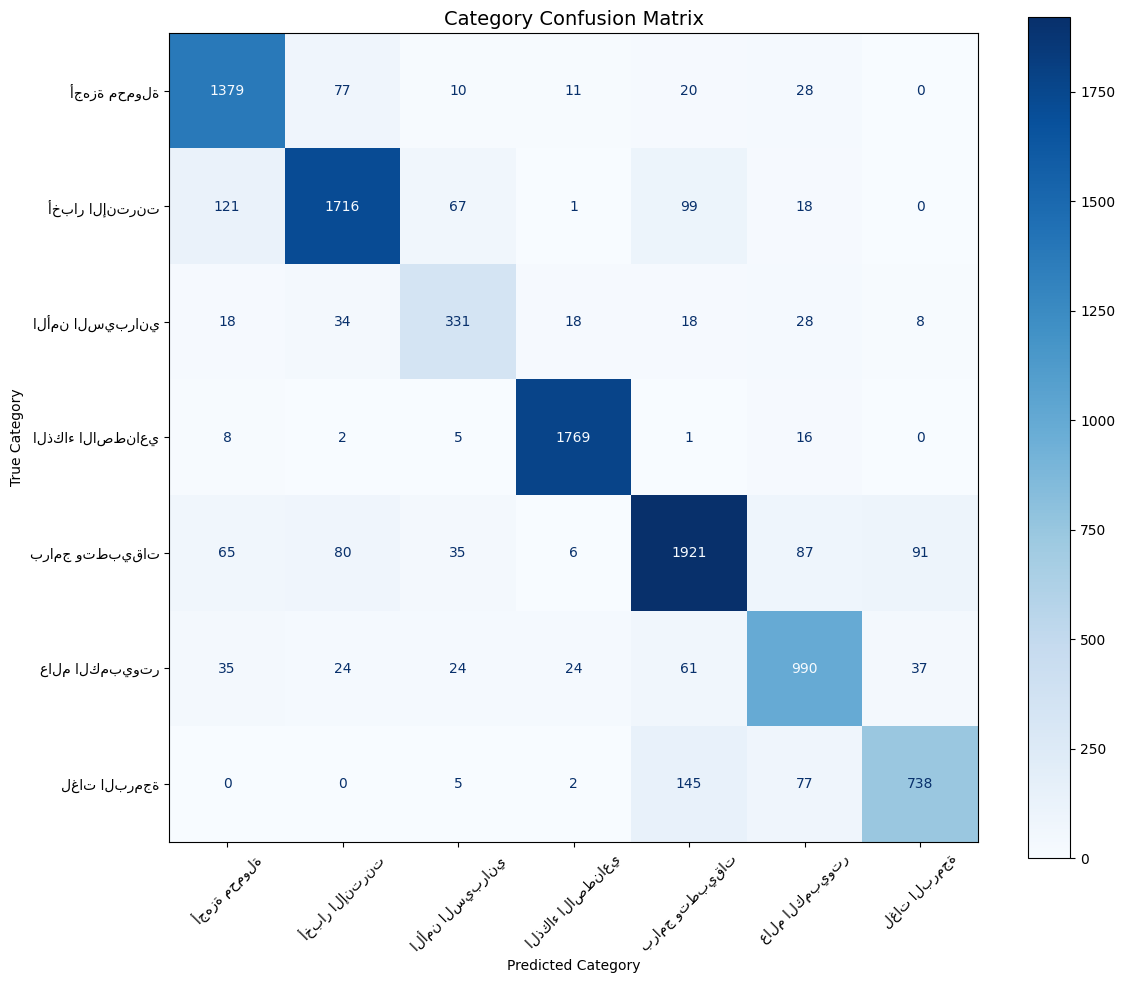

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

unique_labels = sorted(set(decoded_labels))

if len(unique_labels) <= 20:

    cm = confusion_matrix(
        decoded_labels,
        decoded_preds,
        labels=unique_labels
    )

    fig, ax = plt.subplots(
        figsize=(12, 10)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=unique_labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45
    )

    ax.set_title(
        "Category Confusion Matrix",
        fontsize=14
    )

    ax.set_xlabel(
        "Predicted Category"
    )

    ax.set_ylabel(
        "True Category"
    )

    plt.tight_layout()
    plt.show()

else:

    print(
        f"⚠️ Too many categories "
        f"({len(unique_labels)}) "
        "for confusion matrix."
    )

In [ ]:
inference_model = model


def classify_article(
    content,
    _model=inference_model,
    _tokenizer=tokenizer,
    max_input_length=MAX_INPUT_LENGTH,
    num_beams=4
):

    """
    تصنيف مقال عربي إلى تصنيف واحد.
    """

    input_text = f"النص:\n{content}"

    inputs = _tokenizer(
        input_text,
        max_length=max_input_length,
        truncation=True,
        return_tensors="pt"
    ).to(_model.device)

    with torch.no_grad():

        outputs = _model.generate(
            **inputs,
            max_length=MAX_TARGET_LENGTH,
            num_beams=num_beams,
            early_stopping=True
        )

    prediction = _tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return prediction.strip()


print("Inference function ready.")

Inference function ready.


In [ ]:
test_sample = dataset["test"][643]

input_text = test_sample["input"]

if input_text.startswith("النص:"):
    sample_content = input_text[len("النص:"):].strip()
else:
    sample_content = input_text.strip()

result = classify_article(
    sample_content
)

print("📝 Article:")
print(
    sample_content[:300] + "..."
    if len(sample_content) > 300
    else sample_content
)

print("\n🎯 True label:")
print(
    test_sample["target"]
)

print("\n🤖 Predicted:")
print(result)

📝 Article:
تسعى هيئة تخطيط الدولة فيالصينللقضاء علىتعدينعملةبيتكوينالرقمية في البلاد، وذلك وفقًا لمسودة قائمة الأنشطة الصناعية التي تسعى الوكالة إلى إيقافها، في إشارة إلى ضغوط الحكومة المتزايدة على قطاع العملة الرقمية.وتعد الصين أكبر سوق في العالم لأجهزة الحاسب المصممة لتعدين عملة بيتكوين، وغيرها من العملات ال...

🎯 True label:
أخبار الإنترنت

🤖 Predicted:
أخبار الإنترنت


In [ ]:
def classify_batch(articles, batch_size=8):

    results = []

    for i in range(
        0,
        len(articles),
        batch_size
    ):

        batch = articles[
            i:i + batch_size
        ]

        input_texts = [
            f"النص:\n{a['content']}"
            for a in batch
        ]

        inputs = tokenizer(
            input_texts,
            max_length=MAX_INPUT_LENGTH,
            truncation=True,
            padding=True,
            return_tensors="pt"
        ).to(model.device)

        with torch.no_grad():

            outputs = model.generate(
                **inputs,
                max_length=MAX_TARGET_LENGTH,
                num_beams=1
            )

        decoded = tokenizer.batch_decode(
            outputs,
            skip_special_tokens=True
        )

        for text in decoded:
            results.append(
                text.strip()
            )

    return results


print("✅ Batch inference function ready.")

print("\nUsage:")
print(
    'results = classify_batch('
    '[{"content": "نص المقال هنا"}]'
    ')'
)

✅ Batch inference function ready.

Usage:
results = classify_batch([{"content": "نص المقال هنا"}])


In [ ]:
from sklearn.metrics import f1_score, classification_report

# الفئات الحقيقية في مشروعنا
true_categories = [
    "أجهزة محمولة",
    "أخبار الإنترنت",
    "الأمن السيبراني",
    "الذكاء الاصطناعي",
    "برامج وتطبيقات",
    "عالم الكمبيوتر",
    "لغات البرمجة"
]

# نأخذ فقط المقالات التي تصنيفها الحقيقي واحد من الفئات السبعة
filtered_true = []
filtered_pred = []

for true, pred in zip(decoded_labels, decoded_preds):
    if true in true_categories:
        filtered_true.append(true)
        filtered_pred.append(pred)

# حساب Macro F1 للفئات السبعة
f1_macro = f1_score(
    filtered_true,
    filtered_pred,
    labels=true_categories,
    average="macro",
    zero_division=0
)

# حساب Weighted F1
f1_weighted = f1_score(
    filtered_true,
    filtered_pred,
    labels=true_categories,
    average="weighted",
    zero_division=0
)

print("=" * 55)
print("        F1-SCORE RESULTS")
print("=" * 55)

print(f"Macro F1    : {f1_macro:.4f}")
print(f"Weighted F1 : {f1_weighted:.4f}")

print("\nF1 لكل تصنيف:")
report = classification_report(
    filtered_true,
    filtered_pred,
    labels=true_categories,
    zero_division=0
)

print(report)

        F1-SCORE RESULTS
Macro F1    : 0.8406
Weighted F1 : 0.8624

F1 لكل تصنيف:
                  precision    recall  f1-score   support

    أجهزة محمولة       0.85      0.90      0.88      1525
  أخبار الإنترنت       0.89      0.85      0.87      2022
 الأمن السيبراني       0.69      0.73      0.71       455
الذكاء الاصطناعي       0.97      0.98      0.97      1806
  برامج وتطبيقات       0.85      0.84      0.84      2285
  عالم الكمبيوتر       0.80      0.83      0.81      1195
    لغات البرمجة       0.84      0.76      0.80       967

       micro avg       0.86      0.86      0.86     10255
       macro avg       0.84      0.84      0.84     10255
    weighted avg       0.86      0.86      0.86     10255



In [ ]:
# 🤖 استدعاء النموذج المحفوظ وتجربته
import os
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM


MODEL_PATH = "/content/drive/MyDrive/arat5_classifier_version2/final_model"

print("=" * 70)
print("🤖 تحميل النموذج")
print("=" * 70)

print(f"📂 المسار:")
print(MODEL_PATH)

print("\n⏳ تحميل Tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

print("✅ تم تحميل Tokenizer")

print("\n⏳ تحميل النموذج...")

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_PATH)

device = "cuda" if torch.cuda.is_available() else "cpu"

model.to(device)
model.eval()

print("✅ تم تحميل النموذج بنجاح")
print(f"🖥️ الجهاز المستخدم: {device}")


def classify_article(content):

    input_text = f"النص:\n{content}"

    inputs = tokenizer(
        input_text,
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_length=16,
            num_beams=4,
            early_stopping=True
        )

    prediction = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    ).strip()

    return prediction


#  تجربة النموذج

article = """
أعلنت شركة تقنية عن تطوير نظام جديد يعتمد على الذكاء الاصطناعي
لمساعدة المستخدمين في تحليل الصور والتعرف على الأشياء
بشكل أسرع وأكثر دقة.
"""

result = classify_article(article)

print("\n" + "=" * 70)
print("📝 المقال")
print("=" * 70)

print(article)

print("\n" + "=" * 70)
print("🤖 التصنيف المتوقع")
print("=" * 70)

print(result)

print("\n" + "=" * 70)
print("✅ انتهت التجربة")
print("=" * 70)

🤖 تحميل النموذج
📂 المسار:
/content/drive/MyDrive/arat5_classifier_version2/final_model

⏳ تحميل Tokenizer...
✅ تم تحميل Tokenizer

⏳ تحميل النموذج...


Loading weights:   0%|          | 0/281 [00:00<?, ?it/s]

✅ تم تحميل النموذج بنجاح
🖥️ الجهاز المستخدم: cuda

📝 المقال

أعلنت شركة تقنية عن تطوير نظام جديد يعتمد على الذكاء الاصطناعي
لمساعدة المستخدمين في تحليل الصور والتعرف على الأشياء
بشكل أسرع وأكثر دقة.


🤖 التصنيف المتوقع
الذكاء الاصطناعي

✅ انتهت التجربة


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_PATH = "/content/drive/MyDrive/arat5_classifier_version2/final_model"

print("⏳ Loading saved model...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_PATH)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
model.eval()

print("✅ Model loaded successfully!")
print("Device:", device)

⏳ Loading saved model...


Loading weights:   0%|          | 0/281 [00:00<?, ?it/s]

✅ Model loaded successfully!
Device: cpu


In [ ]:
def classify_article(content):
    if not content or not content.strip():
        return "⚠️ اكتب نص المقال أولاً."

    input_text = f"النص:\n{content}"

    inputs = tokenizer(
        input_text,
        max_length=512,
        truncation=True,
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=16,
            num_beams=4,
            early_stopping=True
        )

    prediction = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    ).strip()

    return prediction

In [ ]:
import json

TEST_FILE = "/content/drive/MyDrive/model_dataset/test.json"

with open(TEST_FILE, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print(f"✅ تم تحميل {len(test_data):,} مقال من Test Set")

✅ تم تحميل 10,255 مقال من Test Set


In [ ]:
import gradio as gr
import random


def get_random_article():

    # اختيار رقم عشوائي
    random_number = random.randint(1, len(test_data))

    # جلب المقال
    article = test_data[random_number - 1]

    content = article["content"]
    true_category = str(article["category"])

    return (
        random_number,
        content,
        true_category,
        "🎲 تم اختيار مقال عشوائي"
    )


def classify_from_interface(content):

    if not content or not content.strip():
        return "⚠️ اكتب أو اجلب مقالًا أولًا."

    return classify_article(content)


with gr.Blocks() as interface:

    gr.Markdown(
        """
        # 🤖 مصنف الأخبار التقنية العربية
        ### اختر مقالًا عشوائيًا من Test Set ثم قم بتصنيفه
        """
    )

    # اختيار مقال عشوائي
    with gr.Row():

        test_number = gr.Number(
            label="🔢 رقم المقال المختار",
            interactive=False
        )

        get_button = gr.Button(
            "🎲 اختيار مقال عشوائي"
        )

    # الحالة
    status = gr.Textbox(
        label="الحالة",
        interactive=False
    )

    # نص المقال
    article_text = gr.Textbox(
        label="📰 نص المقال",
        lines=12,
        placeholder="سيظهر المقال هنا..."
    )

    # التصنيف الحقيقي
    true_category = gr.Textbox(
        label="🏷️ التصنيف الحقيقي",
        interactive=False
    )

    # زر التصنيف
    classify_button = gr.Button(
        "🤖 تصنيف المقال"
    )

    # نتيجة النموذج
    predicted_category = gr.Textbox(
        label="🔮 تصنيف النموذج",
        interactive=False
    )

    # زر المقال العشوائي
    get_button.click(
        fn=get_random_article,
        inputs=[],
        outputs=[
            test_number,
            article_text,
            true_category,
            status
        ]
    )

    # زر التصنيف
    classify_button.click(
        fn=classify_from_interface,
        inputs=article_text,
        outputs=predicted_category
    )


interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8f7550ec35ccb88795.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
